# Text Analysis – SMS Spam Collection
This notebook cleans SMS messages, analyzes word frequencies, compares Ham and Spam messages, and saves the cleaned dataset.

In [1]:
from google.colab import files

uploaded = files.upload()

Saving bd-a1.zip to bd-a1.zip


In [2]:
import zipfile
import os

with zipfile.ZipFile('bd-a1.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("Files extracted successfully!")

Files extracted successfully!


In [3]:
import pandas as pd

df = pd.read_csv('/content/bd-a1/data/Dataset.csv')

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Output Folder

In [4]:
os.makedirs('/content/output/figures', exist_ok=True)

print("Figures folder created successfully!")

Figures folder created successfully!


## 1. Text Cleaning

In [5]:
import html
import re

def clean_text(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r"(?<=[a-z])'(?=[a-z])", '', text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_text'] = df['message'].fillna('').apply(clean_text)

df[['message', 'cleaned_text']].head(10)

,message,cleaned_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been weeks now a...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile months or more u r entitled to...


## 2. Tokenization and Basic Statistics

In [6]:
df['tokens'] = df['cleaned_text'].apply(lambda x: x.split())

total_tokens = sum(df['tokens'].apply(len))

all_words = [word for tokens in df['tokens'] for word in tokens]

unique_words = set(all_words)

average_words = total_tokens / len(df)

print("Total Tokens:", total_tokens)
print("Unique Words:", len(unique_words))
print("Average Words per Record:", round(average_words, 2))

Total Tokens: 84592
Unique Words: 7805
Average Words per Record: 15.18


## 3. Most Frequent Words

In [7]:
from collections import Counter

word_counts = Counter(all_words)

top_20 = word_counts.most_common(20)

top_20_df = pd.DataFrame(top_20, columns=['Word', 'Frequency'])

top_20_df

,Word,Frequency
0,i,2392
1,to,2253
2,you,2158
3,a,1466
4,the,1343
5,u,1203
6,and,980
7,in,907
8,is,896
9,me,807


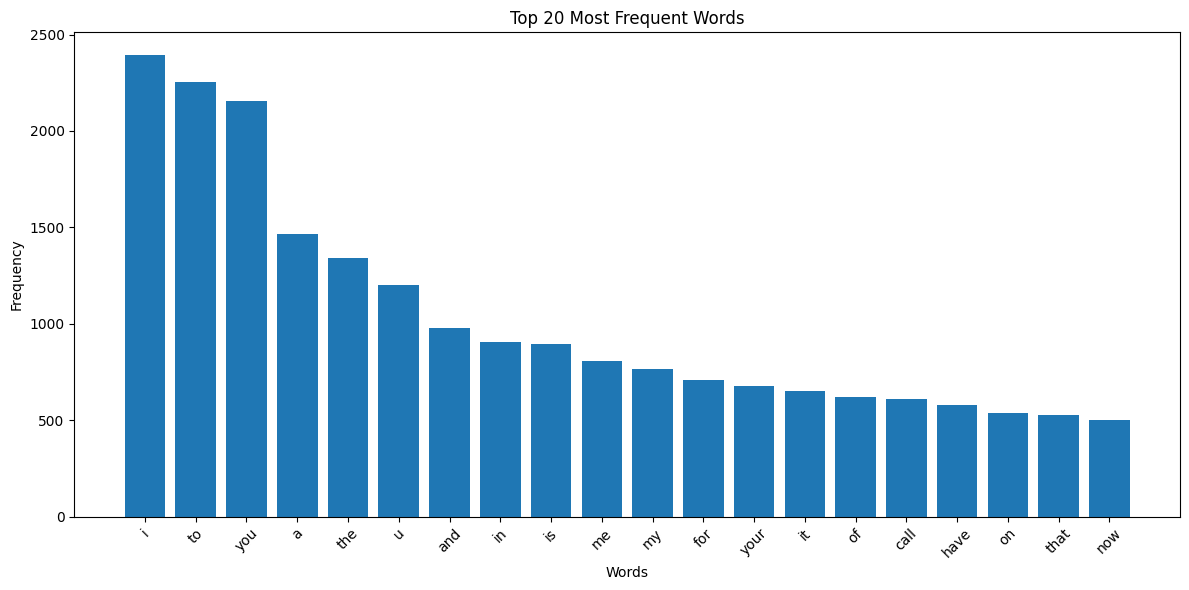

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(top_20_df['Word'], top_20_df['Frequency'])

plt.title('Top 20 Most Frequent Words')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('/content/output/figures/top_20_words.png')
plt.show()

## 4. Spam vs Ham Comparison

In [9]:
df['text_length'] = df['cleaned_text'].apply(len)
df['word_count'] = df['tokens'].apply(len)

group_comparison = df.groupby('label').agg(
    average_text_length=('text_length', 'mean'),
    average_word_count=('word_count', 'mean')
)

group_comparison

,average_text_length,average_word_count
label,,
ham,66.499482,14.079171
spam,112.937082,22.302544


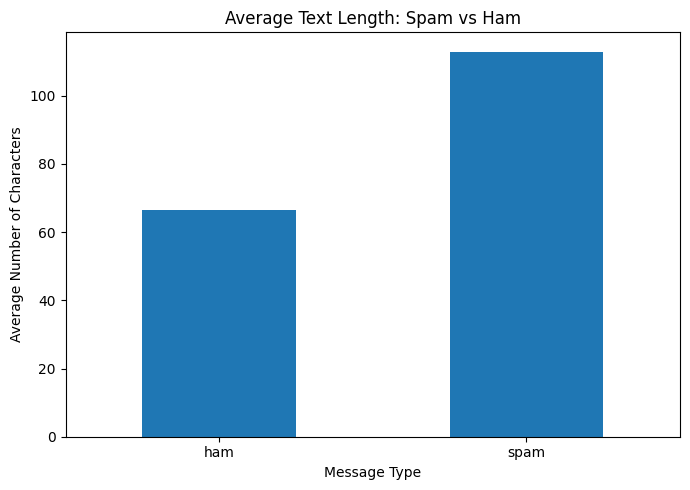

In [10]:
plt.figure(figsize=(7, 5))

group_comparison['average_text_length'].plot(kind='bar')

plt.title('Average Text Length: Spam vs Ham')
plt.xlabel('Message Type')
plt.ylabel('Average Number of Characters')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('/content/output/figures/average_text_length.png')
plt.show()

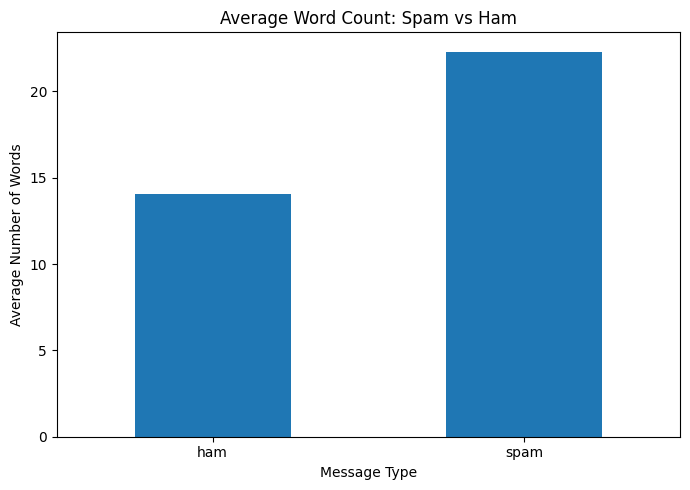

In [11]:
plt.figure(figsize=(7, 5))

group_comparison['average_word_count'].plot(kind='bar')

plt.title('Average Word Count: Spam vs Ham')
plt.xlabel('Message Type')
plt.ylabel('Average Number of Words')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('/content/output/figures/average_word_count.png')
plt.show()

## 5. Top 10 Words by Message Type

In [12]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ham_words = [
    word for tokens in df[df['label'] == 'ham']['tokens']
    for word in tokens
    if word not in ENGLISH_STOP_WORDS
]

spam_words = [
    word for tokens in df[df['label'] == 'spam']['tokens']
    for word in tokens
    if word not in ENGLISH_STOP_WORDS
]

ham_top_10 = Counter(ham_words).most_common(10)
spam_top_10 = Counter(spam_words).most_common(10)

print("Ham Top 10:", ham_top_10)
print("Spam Top 10:", spam_top_10)

Ham Top 10: [('u', 1028), ('im', 466), ('just', 297), ('ok', 288), ('dont', 268), ('ur', 247), ('know', 237), ('good', 235), ('got', 234), ('like', 234)]
Spam Top 10: [('free', 228), ('p', 180), ('u', 175), ('txt', 166), ('ur', 144), ('mobile', 129), ('stop', 128), ('text', 125), ('claim', 113), ('reply', 104)]


## 6. Stop-word Removal Comparison

In [13]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

filtered_words = [
    word for word in all_words
    if word not in ENGLISH_STOP_WORDS
]

filtered_counts = Counter(filtered_words)

top_20_no_stopwords = pd.DataFrame(
    filtered_counts.most_common(20),
    columns=['Word', 'Frequency']
)

top_20_no_stopwords

,Word,Frequency
0,u,1203
1,im,481
2,ur,391
3,just,376
4,ok,293
5,dont,291
6,free,288
7,know,262
8,like,247
9,good,247


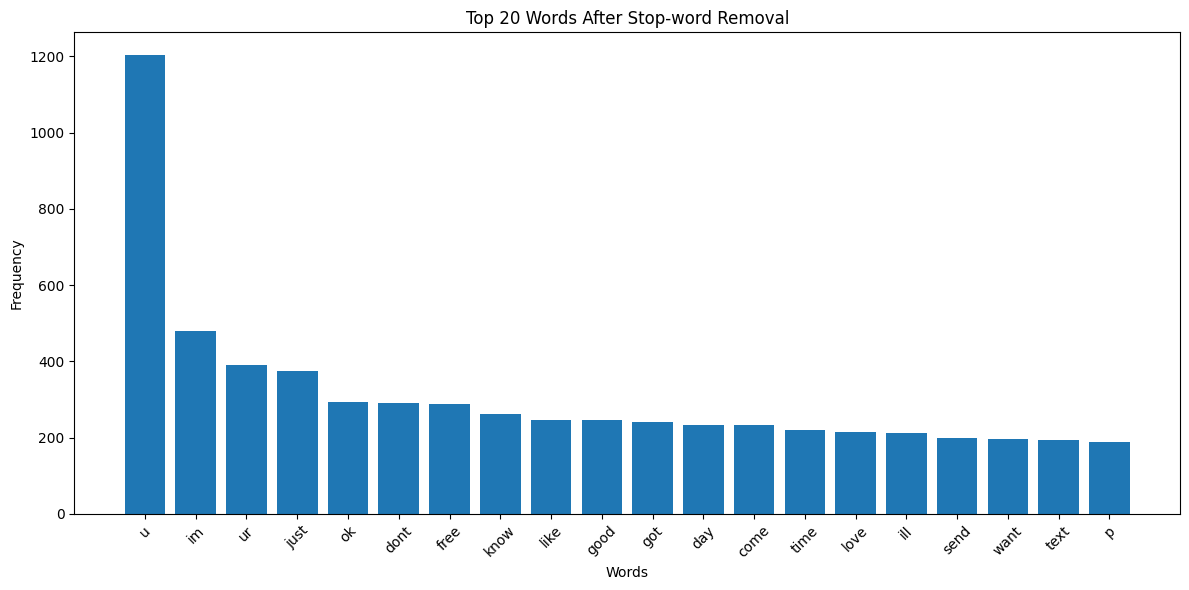

In [14]:
plt.figure(figsize=(12, 6))
plt.bar(top_20_no_stopwords['Word'], top_20_no_stopwords['Frequency'])

plt.title('Top 20 Words After Stop-word Removal')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('/content/output/figures/top_20_words_without_stopwords.png')
plt.show()

## 7. Save Cleaned Dataset

In [15]:
import os

os.makedirs('/content/output', exist_ok=True)

df[['label', 'message', 'cleaned_text']].to_csv(
    '/content/output/cleaned_data.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 8. Key Insights

## Text Analysis

**1. Class Distribution**
- **Observation:** The dataset contains more Ham messages than Spam messages.
- **Evidence:** There are 4,825 Ham messages and 747 Spam messages.
- **Interpretation:** The dataset is imbalanced because Ham messages represent the majority of the data.

**2. Message Length**
- **Observation:** Spam messages are longer than Ham messages.
- **Evidence:** The average message length is 112.94 characters for Spam and 66.50 characters for Ham.
- **Interpretation:** Spam messages tend to include more promotional details and information.

**3. Word Count**
- **Observation:** Spam messages contain more words on average.
- **Evidence:** Spam messages have an average of 22.30 words, compared with 14.08 words for Ham.
- **Interpretation:** Spam messages tend to use more words to communicate offers or attract attention.

**4. Common Words in Spam**
- **Observation:** Spam messages frequently contain promotional words.
- **Evidence:** Words such as "free", "txt", "mobile", "claim", and "reply" appear in the top 10 Spam words.
- **Interpretation:** These words suggest that many Spam messages are related to promotions, offers, and requests for replies.

**5. Common Words in Ham**
- **Observation:** Ham messages contain more conversational words.
- **Evidence:** Words such as "just", "ok", "dont", "know", and "good" appear in the top 10 Ham words.
- **Interpretation:** These words reflect everyday communication and informal conversations.